<a href="https://colab.research.google.com/github/iindrisw/PROJEK-MACHINE-LEARNING-1/blob/main/03_varian_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Fitur akhir yang masuk ke model: ['G1', 'G2', 'studytime', 'absences', 'failures', 'Medu', 'address_U', 'higher_yes']

=== HASIL VARIAN 3 (PEMILIHAN FITUR) ===
MAE  : 0.7370
RMSE : 1.1640
R2   : 0.8610


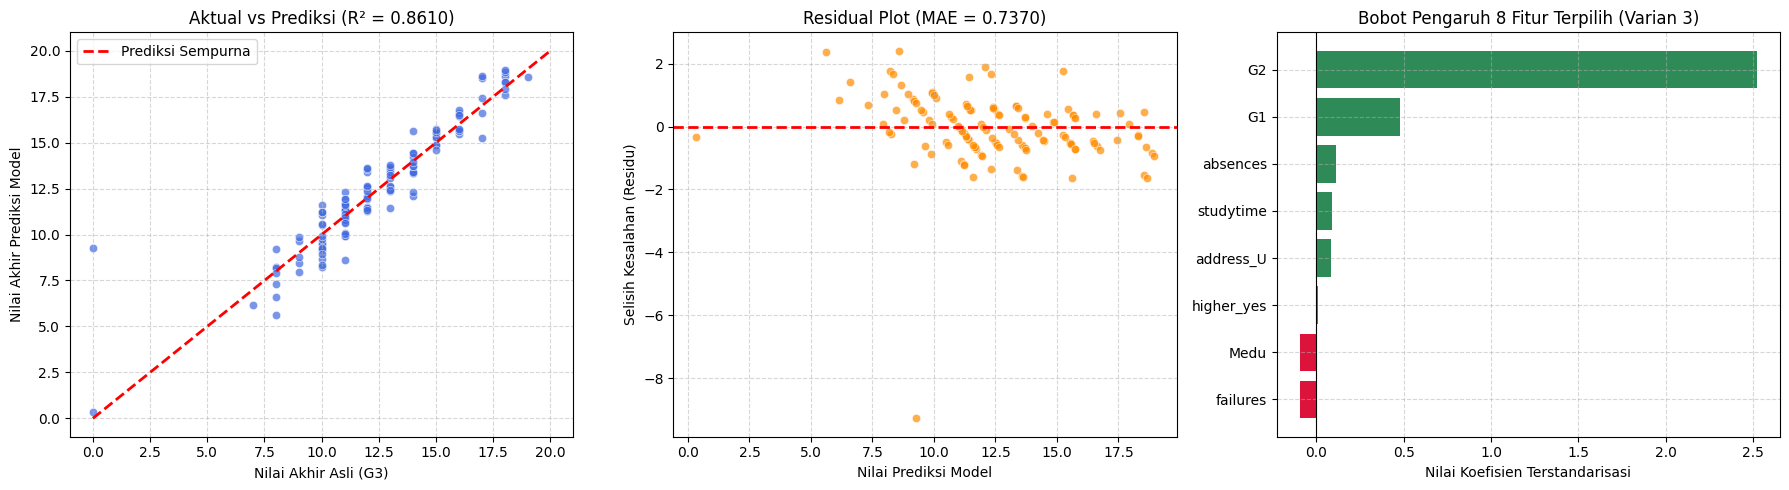

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load data bersih
df = pd.read_csv('student_por_clean.csv')

# 1. Tentukan fitur terpilih (berdasarkan korelasi & domain)
fitur_numerik_terpilih = ['G1', 'G2', 'studytime', 'absences', 'failures', 'Medu']
fitur_kategorikal_terpilih = ['address', 'higher']

# 2. One-Hot Encoding untuk fitur kategorikal
df_encoded = pd.get_dummies(
    df[fitur_numerik_terpilih + fitur_kategorikal_terpilih + ['G3']],
    columns=fitur_kategorikal_terpilih,
    drop_first=True
)

X = df_encoded.drop(columns=['G3'])
y = df_encoded['G3']

print("Fitur akhir yang masuk ke model:", X.columns.tolist())

# 3. Split data TERLEBIH DAHULU sebelum scaling
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Penskalaan
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Latih model & Evaluasi
model_v3 = LinearRegression()
model_v3.fit(X_train_scaled, y_train)

y_pred = model_v3.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n=== HASIL VARIAN 3 (PEMILIHAN FITUR) ===")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

# 6. Visualisasi Hasil Evaluasi Model Varian 3
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafik A: Nilai Aktual (y_test) vs Nilai Prediksi (y_pred)
sns.scatterplot(x=y_test, y=y_pred, color='royalblue', alpha=0.7, ax=axes[0])
axes[0].plot([0, 20], [0, 20], color='red', linestyle='--', linewidth=2, label='Prediksi Sempurna')
axes[0].set_title(f'Aktual vs Prediksi (R² = {r2:.4f})')
axes[0].set_xlabel('Nilai Akhir Asli (G3)')
axes[0].set_ylabel('Nilai Akhir Prediksi Model')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Grafik B: Sebaran Residu (Selisih Kesalahan = Aktual - Prediksi)
residu = y_test - y_pred
sns.scatterplot(x=y_pred, y=residu, color='darkorange', alpha=0.7, ax=axes[1])
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title(f'Residual Plot (MAE = {mae:.4f})')
axes[1].set_xlabel('Nilai Prediksi Model')
axes[1].set_ylabel('Selisih Kesalahan (Residu)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Grafik C: Bobot Koefisien Fitur (Setelah StandardScaler)
coef_df = pd.DataFrame({
    'Fitur': X.columns,
    'Koefisien': model_v3.coef_
}).sort_values(by='Koefisien', ascending=True)

colors = ['crimson' if c < 0 else 'seagreen' for c in coef_df['Koefisien']]
axes[2].barh(coef_df['Fitur'], coef_df['Koefisien'], color=colors)
axes[2].axvline(0, color='black', linewidth=0.8)
axes[2].set_title('Bobot Pengaruh 8 Fitur Terpilih (Varian 3)')
axes[2].set_xlabel('Nilai Koefisien Terstandarisasi')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()